Importing necessary libraries

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt

import json
import pandas as pd
from ipywidgets import interact, IntSlider
from IPython.display import display, Markdown, Image

from pathlib import Path

import string
import re

Play with 510.csv data

In [2]:
file_path_510 = Path(r"C:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\newyorker_caption_contest\data\510.csv")

df = pd.read_csv(file_path_510)

# Show first 5 rows
print("First 5 rows:")
print(df.head())

First 5 rows:
   rank                                            caption      mean  \
0     0          I'm a congressman--obstruction is my job.  1.913043   
1     1  I'm what they mean when they say, 'The middle ...  1.842105   
2     2                  Does this suit make me look flat?  1.711111   
3     3    When the right woman comes along, I'll know it.  1.625000   
4     4  I used to lie in the gutter, but then I quit d...  1.617647   

   precision  votes  not_funny  somewhat_funny  funny  
0   0.094022     69         24              27     18  
1   0.191381     19          8               6      5  
2   0.112915     45         21              16      8  
3   0.116657     32         15              14      3  
4   0.133610     34         19               9      6  


Clean the text to analyse it better:

In [ ]:
df["caption"] = df["caption"].str.replace(r"[--]", " ", regex=True)
df["caption"] = df["caption"].str.replace(r"[.,?]", " ", regex=True)

# Save the cleaned version
df.to_csv("cleaned_file.csv", index=False)

print(df["caption"].head())


0            I'm a congressman  obstruction is my job 
1    I'm what they mean when they say  'The middle ...
2                    Does this suit make me look flat 
3      When the right woman comes along  I'll know it 
4    I used to lie in the gutter  but then I quit d...
Name: caption, dtype: object


In [4]:
# get rid of unnecessary punctuation and turn everything to lower case
df["caption"] = (
    df["caption"]
    .astype(str)                                 # ensure strings, preserves NaN as "nan" if needed
    .str.replace(r"[—–-]+", " ", regex=True)     # replace em/en/ASCII hyphens (one or more) with a space
    .str.replace(r"[.,?]", "", regex=True)       # remove commas, periods and question marks
    .str.lower()                                 # lowercase
    .str.replace(r"\s+", " ", regex=True)        # collapse multiple spaces
    .str.strip()                                 # trim edges
)

print(df["caption"].tolist()) # check if it works


["i'm a congressman obstruction is my job", "i'm what they mean when they say 'the middle class is getting stepped on '", 'does this suit make me look flat', "when the right woman comes along i'll know it", 'i used to lie in the gutter but then i quit drinking', 'if you can meditate here you can meditate anywhere', 'sorry for the inconvenience i probably should have jumped from a higher window', "i've decided to take it lying down", 'anyone who steps on me is out!', 'guess i should have jumped from a few floors higher', 'my life has become so pedestrian', 'i may have misinterpreted one of the twelve steps', 'i should have jumped from a higher floor', "i'm doing a study on the indifference of man so far you're all doing great!", "walk around i'm occupying wall street", "i'm waiting for the chalk guy", 'you probably know my column: man on the street', 'will move for food', 'my therapist is right i do let everyone walk all over me', "it's the only place that i don't get stepped on", 'brot

In [7]:
import sys
print(sys.executable)

!{sys.executable} -m pip install contractions

c:\Users\mered\anaconda3\python.exe
  Obtaining dependency information for contractions from https://files.pythonhosted.org/packages/bb/e4/725241b788963b460ce0118bfd5c505dd3d1bdd020ee740f9f39044ed4a7/contractions-0.1.73-py2.py3-none-any.whl.metadata
  Obtaining dependency information for textsearch>=0.0.21 from https://files.pythonhosted.org/packages/e2/0f/6f08dd89e9d71380a369b1f5b6c97a32d62fc9cfacc1c5b8329505b9e495/textsearch-0.0.24-py2.py3-none-any.whl.metadata
  Obtaining dependency information for anyascii from https://files.pythonhosted.org/packages/c2/76/783b75a21ce3563b8709050de030ae253853b147bd52e141edc1025aa268/anyascii-0.3.3-py3-none-any.whl.metadata
  Obtaining dependency information for pyahocorasick from https://files.pythonhosted.org/packages/ac/06/d956a977db3cfa6f58cc031ca3e728bf7fc24076b5e040927b2fad2eb5e3/pyahocorasick-2.2.0-cp311-cp311-win_amd64.whl.metadata
   ---------------------------------------- 0.0/345.1 kB ? eta -:--:--
   - -----------------------------------

In [9]:
# handle contractions -> for this do "pip install contractions"

import contractions 

df["caption"] = df["caption"].apply(lambda x: contractions.fix(x))   

print(df["caption"].tolist()) # check if it works

['i am a congressman obstruction is my job', "i am what they mean when they say 'the middle class is getting stepped on '", 'does this suit make me look flat', 'when the right woman comes along i will know it', 'i used to lie in the gutter but then i quit drinking', 'if you can meditate here you can meditate anywhere', 'sorry for the inconvenience i probably should have jumped from a higher window', 'i have decided to take it lying down', 'anyone who steps on me is out!', 'guess i should have jumped from a few floors higher', 'my life has become so pedestrian', 'i may have misinterpreted one of the twelve steps', 'i should have jumped from a higher floor', 'i am doing a study on the indifference of man so far you are all doing great!', 'walk around i am occupying wall street', 'i am waiting for the chalk guy', 'you probably know my column: man on the street', 'will move for food', 'my therapist is right i do let everyone walk all over me', 'it is the only place that i do not get steppe

Count the number of words in each line and look if there is a correlation between length and score 

In [25]:
# words per line
df["word_counts"] = [len(line.split()) for line in df["caption"]]
print(df["word_counts"])

# characters per line
df["length"] = [len(line) for line in df["caption"]]

# average length in this csv file (501) 
print("Basic statistics:")
print(f"Average word count: {df['word_counts'].mean():.2f}")
print(f"Average character count: {df['length'].mean():.2f}")
print(f"Dataset size: {len(df)} captions")


0        8
1       16
2        7
3       10
4       12
        ..
3900    12
3901     9
3902     8
3903     8
3904     6
Name: word_counts, Length: 3905, dtype: int64
Basic statistics:
Average word count: 9.85
Average character count: 48.68
Dataset size: 3905 captions


In [26]:
# import libraries for data plotting and analysis
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# plotting style
plt.style.use('default')
sns.set_palette("husl")

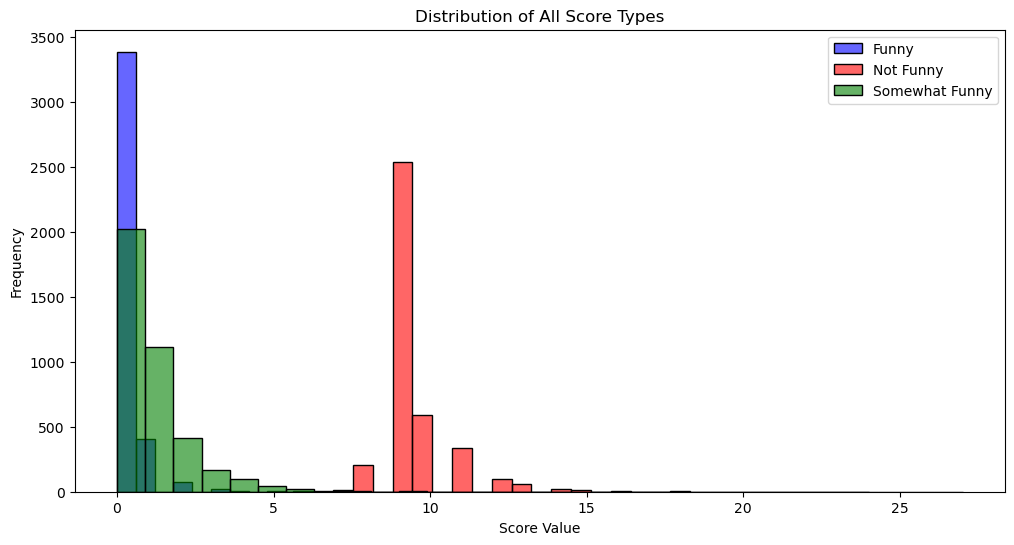

In [35]:
# scores
df['all_votes'] = df['not_funny'] + df['funny'] + df['somewhat_funny']

# check score distribution

plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='funny', bins=30, alpha=0.6, label='Funny', color='blue')
sns.histplot(data=df, x='not_funny', bins=30, alpha=0.6, label='Not Funny', color='red')
sns.histplot(data=df, x='somewhat_funny', bins=30, alpha=0.6, label='Somewhat Funny', color='green')
plt.title('Distribution of All Score Types')
plt.xlabel('Score Value')
plt.ylabel('Frequency')
plt.legend()
plt.show()




In [37]:
# total votes for each caption
df['total_votes'] = df['not_funny'] + df['somewhat_funny'] + df['funny']

# proportions for each category
df['prop_not_funny'] = df['not_funny'] / df['total_votes']
df['prop_somewhat_funny'] = df['somewhat_funny'] / df['total_votes']
df['prop_funny'] = df['funny'] / df['total_votes']

print(f"\nVote summary:")
print(f"Total votes across all captions: {df['total_votes'].sum()}")
print(f"Average votes per caption: {df['total_votes'].mean():.1f}")

# create a Composite "Funny Score"

# weighted average (funny=2, somewhat_funny=1, not_funny=0)
df['funny_score_weighted'] = (df['funny'] * 2 + df['somewhat_funny'] * 1 + df['not_funny'] * 0) / df['total_votes']

df['success_metric'] = df['funny_score_weighted']

print(f"\nSuccess metric range: {df['success_metric'].min():.3f} to {df['success_metric'].max():.3f}")




Vote summary:
Total votes across all captions: 41185
Average votes per caption: 10.5

Success metric range: 0.000 to 0.913


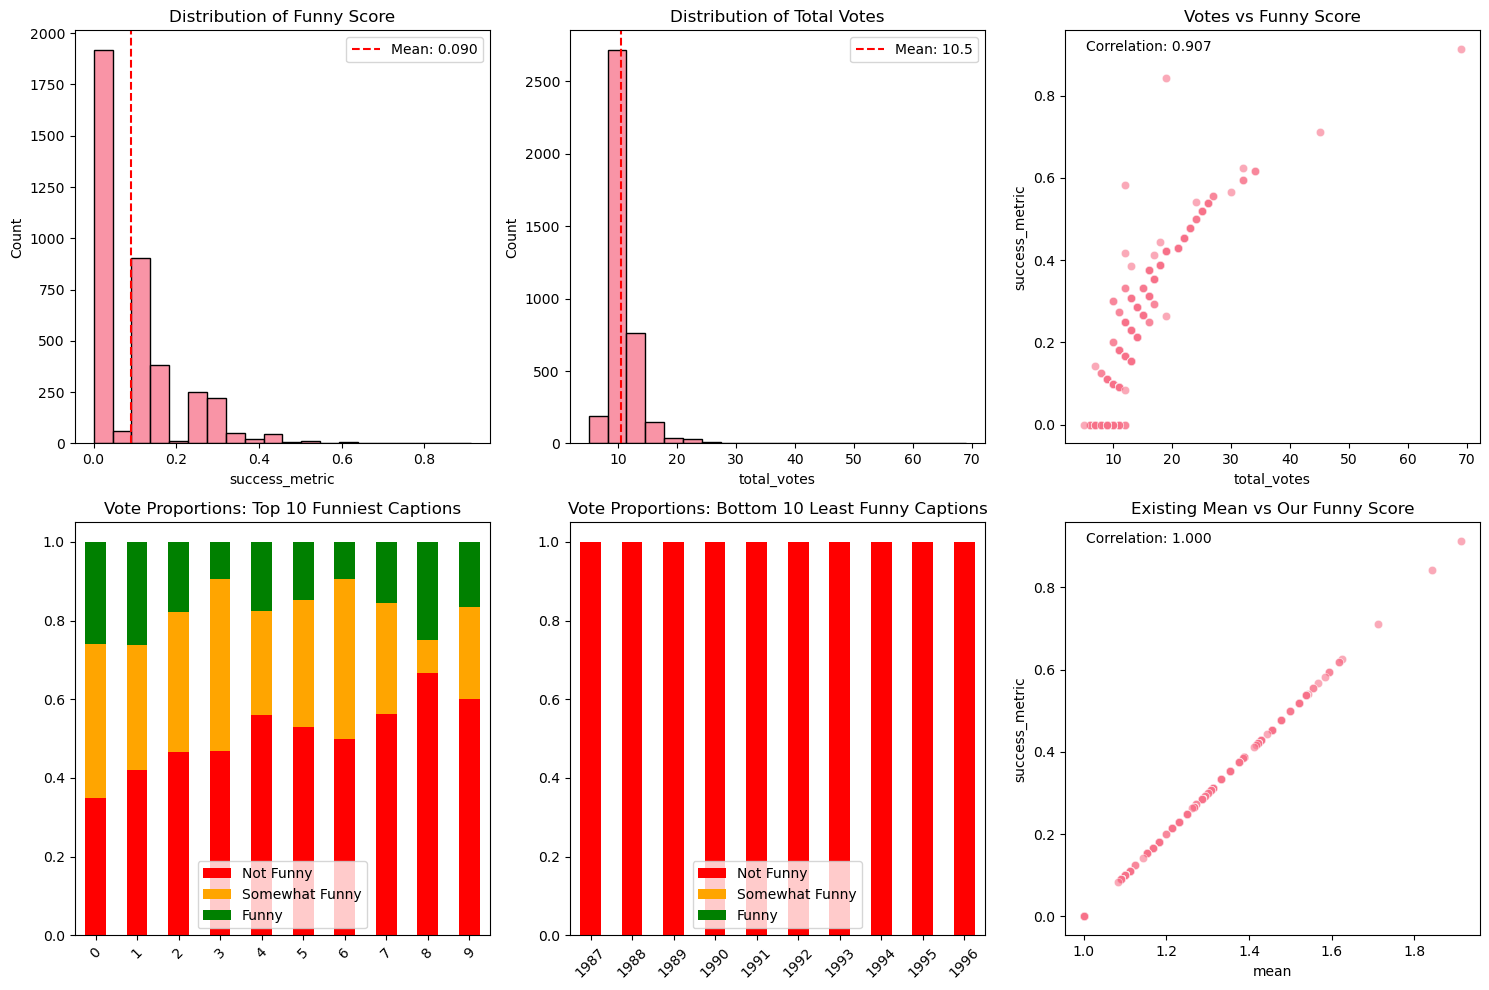

In [38]:
# distribution Analysis

plt.figure(figsize=(15, 10))

    # distribution of success metric
plt.subplot(2, 3, 1)
sns.histplot(data=df, x='success_metric', bins=20)
plt.title('Distribution of Funny Score')
plt.axvline(df['success_metric'].mean(), color='red', linestyle='--', label=f"Mean: {df['success_metric'].mean():.3f}")
plt.legend()

    # vote distribution
plt.subplot(2, 3, 2)
sns.histplot(data=df, x='total_votes', bins=20)
plt.title('Distribution of Total Votes')
plt.axvline(df['total_votes'].mean(), color='red', linestyle='--', label=f"Mean: {df['total_votes'].mean():.1f}")
plt.legend()

    # correlation between votes and success
plt.subplot(2, 3, 3)
sns.scatterplot(data=df, x='total_votes', y='success_metric', alpha=0.6)
plt.title('Votes vs Funny Score')
corr_votes = df['total_votes'].corr(df['success_metric'])
plt.text(0.05, 0.95, f'Correlation: {corr_votes:.3f}', transform=plt.gca().transAxes)

    # proportion breakdown for top captions
plt.subplot(2, 3, 4)
top_10 = df.nlargest(10, 'success_metric')[['prop_not_funny', 'prop_somewhat_funny', 'prop_funny']]
top_10.plot(kind='bar', stacked=True, ax=plt.gca(), 
            color=['red', 'orange', 'green'])
plt.title('Vote Proportions: Top 10 Funniest Captions')
plt.xticks(rotation=45)
plt.legend(['Not Funny', 'Somewhat Funny', 'Funny'])

    # proportion breakdown for bottom captions
plt.subplot(2, 3, 5)
bottom_10 = df.nsmallest(10, 'success_metric')[['prop_not_funny', 'prop_somewhat_funny', 'prop_funny']]
bottom_10.plot(kind='bar', stacked=True, ax=plt.gca(), 
               color=['red', 'orange', 'green'])
plt.title('Vote Proportions: Bottom 10 Least Funny Captions')
plt.xticks(rotation=45)
plt.legend(['Not Funny', 'Somewhat Funny', 'Funny'])

    # relationship between existing 'mean' and our new score
plt.subplot(2, 3, 6)
sns.scatterplot(data=df, x='mean', y='success_metric', alpha=0.6)
plt.title('Existing Mean vs Our Funny Score')
corr_mean = df['mean'].corr(df['success_metric'])
plt.text(0.05, 0.95, f'Correlation: {corr_mean:.3f}', transform=plt.gca().transAxes)

plt.tight_layout()
plt.show()



Correlation with Funny Score:
Word count correlation: -0.069 (p-value: 0.000)
Character count correlation: -0.075 (p-value: 0.000)


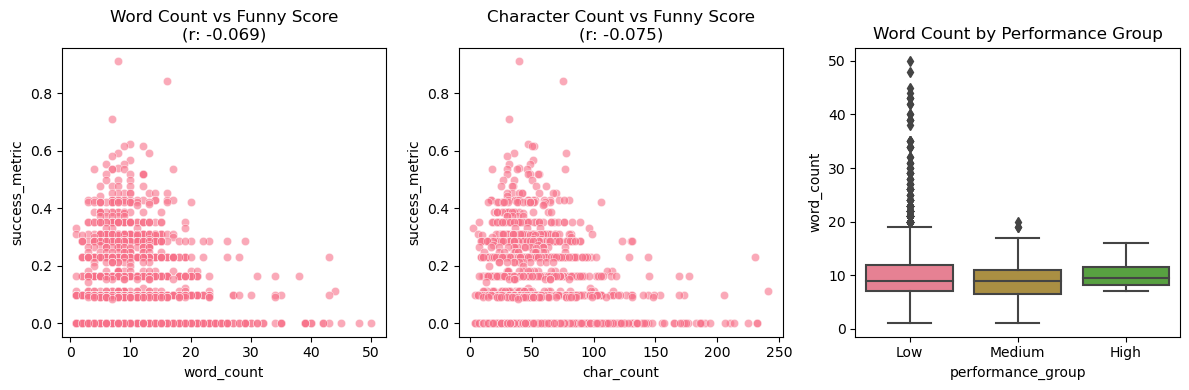

In [43]:

# text Analysis with Proper Success Metric
    # Correlation analysis
corr_word_score, p_word = pearsonr(df['word_counts'], df['success_metric'])
corr_char_score, p_char = pearsonr(df['length'], df['success_metric'])

print(f"\nCorrelation with Funny Score:")
print(f"Word count correlation: {corr_word_score:.3f} (p-value: {p_word:.3f})")
print(f"Character count correlation: {corr_char_score:.3f} (p-value: {p_char:.3f})")

# Visualization
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df, x='word_count', y='success_metric', alpha=0.6)
plt.title(f'Word Count vs Funny Score\n(r: {corr_word_score:.3f})')

plt.subplot(1, 3, 2)
sns.scatterplot(data=df, x='char_count', y='success_metric', alpha=0.6)
plt.title(f'Character Count vs Funny Score\n(r: {corr_char_score:.3f})')

plt.subplot(1, 3, 3)
# Create performance groups for comparison
df['performance_group'] = pd.cut(df['success_metric'], bins=3, labels=['Low', 'Medium', 'High'])

sns.boxplot(data=df, x='performance_group', y='word_count')
plt.title('Word Count by Performance Group')

plt.tight_layout()
plt.show()


In [45]:

# compare Top vs Bottom Performers
from scipy.stats import ttest_ind 

# Define top and bottom performers (e.g., top 20% vs bottom 20%)
top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nPerformance Comparison:")
print(f"Top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"Bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

# Compare metrics
print(f"\nWord count comparison:")
print(f"Top performers: {top_captions['word_count'].mean():.1f} ± {top_captions['word_count'].std():.1f}")
print(f"Bottom performers: {bottom_captions['word_count'].mean():.1f} ± {bottom_captions['word_count'].std():.1f}")

# Statistical test
t_stat, p_val = ttest_ind(top_captions['word_count'], bottom_captions['word_count'])
print(f"T-test p-value: {p_val:.4f}")




Performance Comparison:
Top 20% cutoff: 0.167 (1011 captions)
Bottom 20% cutoff: 0.000 (1918 captions)

Word count comparison:
Top performers: 9.3 ± 4.4
Bottom performers: 10.2 ± 5.5
T-test p-value: 0.0000


In [46]:
# examples

print("\n" + "="*60)
print("EXAMPLE CAPTIONS")
print("="*60)

print("\nTOP 5 FUNNIEST CAPTIONS:")
top_5 = df.nlargest(5, 'success_metric')[['caption', 'success_metric', 'funny', 'somewhat_funny', 'not_funny']]
for idx, row in top_5.iterrows():
    print(f"\nScore: {row['success_metric']:.3f} (Funny: {row['funny']}, Somewhat: {row['somewhat_funny']}, Not: {row['not_funny']})")
    print(f"Caption: {row['caption']}")

print("\nBOTTOM 5 LEAST FUNNY CAPTIONS:")
bottom_5 = df.nsmallest(5, 'success_metric')[['caption', 'success_metric', 'funny', 'somewhat_funny', 'not_funny']]
for idx, row in bottom_5.iterrows():
    print(f"\nScore: {row['success_metric']:.3f} (Funny: {row['funny']}, Somewhat: {row['somewhat_funny']}, Not: {row['not_funny']})")
    print(f"Caption: {row['caption']}")


# quick Sentiment Analysis

#  check on top vs bottom

import nltk
from nltk.sentiment import SentimentIntensityAnalyzer as sia

def quick_sentiment(text):
    return sia.polarity_scores(text)['compound']

top_captions['sentiment'] = top_captions['caption'].apply(quick_sentiment)
bottom_captions['sentiment'] = bottom_captions['caption'].apply(quick_sentiment)

print(f"\nSentiment Comparison:")
print(f"Top performers sentiment: {top_captions['sentiment'].mean():.3f}")
print(f"Bottom performers sentiment: {bottom_captions['sentiment'].mean():.3f}")

sentiment_t, sentiment_p = ttest_ind(top_captions['sentiment'], bottom_captions['sentiment'])
print(f"Sentiment t-test p-value: {sentiment_p:.4f}")


EXAMPLE CAPTIONS

TOP 5 FUNNIEST CAPTIONS:

Score: 0.913 (Funny: 18, Somewhat: 27, Not: 24)
Caption: i am a congressman obstruction is my job

Score: 0.842 (Funny: 5, Somewhat: 6, Not: 8)
Caption: i am what they mean when they say 'the middle class is getting stepped on '

Score: 0.711 (Funny: 8, Somewhat: 16, Not: 21)
Caption: does this suit make me look flat

Score: 0.625 (Funny: 3, Somewhat: 14, Not: 15)
Caption: when the right woman comes along i will know it

Score: 0.618 (Funny: 6, Somewhat: 9, Not: 19)
Caption: i used to lie in the gutter but then i quit drinking

BOTTOM 5 LEAST FUNNY CAPTIONS:

Score: 0.000 (Funny: 0, Somewhat: 0, Not: 9)
Caption: that is right just walk all over me you would not be the first

Score: 0.000 (Funny: 0, Somewhat: 0, Not: 10)
Caption: lost my job now my dignity

Score: 0.000 (Funny: 0, Somewhat: 0, Not: 9)
Caption: if i am going to get walked all over it is going to be on *my* terms ["my" in italics]

Score: 0.000 (Funny: 0, Somewhat: 0, Not: 9)
C

TypeError: SentimentIntensityAnalyzer.polarity_scores() missing 1 required positional argument: 'text'

Now lets see if some words correlate with higher scores


In [47]:
from collections import Counter

# first, lets get rid of common words such as "a, the, an, he, she, I..." so that we don't cound them in (these are considered stop words)

from nltk.corpus import stopwords
import nltk

# Download NLTK stopwords (run once)
nltk.download('stopwords')

def get_stopword_lists():
    """Get different stop word lists for different use cases"""
    
    # English stop words
    basic_stopwords = set(stopwords.words('english'))
    
    # Extended stop words - add custom words
    extended_stopwords = basic_stopwords.union({
        'like', 'get', 'would', 'could', 'also', 'us', 'one', 'two', 'three'
    })
    
    # Sentiment-safe stop words (keep negation words)
    sentiment_safe_stopwords = basic_stopwords - {
        'not', 'no', 'nor', 'never', 'none', 'neither', 'do not',  
        'are not', 'could not', 'did not',
        'does not', 'had not', 'has not', 'have not', 'is not', 'might not', 'must not',
        'need not', 'shall not', 'should not', 
        'was not', 'were not', 'will not', 'would not'
    }
    
    return {
        'basic': basic_stopwords,
        'extended': extended_stopwords,
        'sentiment_safe': sentiment_safe_stopwords,
        'custom': set()  # Empty set for no stopword removal
    }

def analyze_with_stopwords(df, caption_column='caption', stopword_type='basic', top_n=20):
    """Analyze word frequency with different stopword options"""
    
    stopword_lists = get_stopword_lists()
    selected_stopwords = stopword_lists[stopword_type]
    
    # Combine all captions
    all_text = ' '.join(df[caption_column].dropna().astype(str))
    
    # Clean and tokenize
    words = re.findall(r'\b[a-zA-Z]+\b', all_text.lower())
    
    # Remove selected stopwords
    if selected_stopwords:
        words = [word for word in words if word not in selected_stopwords]
    
    # Count frequencies
    word_freq = Counter(words)
    
    return pd.DataFrame(word_freq.most_common(top_n), 
                       columns=['word', 'frequency'])

# Usage examples
print("=== BASIC STOPWORDS REMOVED ===")
basic_results = analyze_with_stopwords(df, 'caption', 'basic', 10)
print(basic_results)

print("\n=== SENTIMENT-SAFE STOPWORDS ===")
sentiment_results = analyze_with_stopwords(df, 'caption', 'sentiment_safe', 10)
print(sentiment_results)

print("\n=== NO STOPWORDS REMOVED ===")
no_stopwords_results = analyze_with_stopwords(df, 'caption', 'custom', 10)
print(no_stopwords_results)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mered\AppData\Roaming\nltk_data...


=== BASIC STOPWORDS REMOVED ===
     word  frequency
0    like        264
1  people        227
2    walk        178
3     new        172
4     get        153
5     one        142
6   would        133
7  street        127
8    life        108
9    look        105

=== SENTIMENT-SAFE STOPWORDS ===
     word  frequency
0     not        519
1    like        264
2  people        227
3    walk        178
4     new        172
5     get        153
6     one        142
7   would        133
8  street        127
9    life        108

=== NO STOPWORDS REMOVED ===
  word  frequency
0    i       1976
1  the       1378
2    a       1042
3   to        958
4   is        827
5   my        662
6   am        661
7  you        623
8   it        553
9   me        538


[nltk_data]   Unzipping corpora\stopwords.zip.


In [ ]:
def get_most_common_words(text_series, n=30, remove_stopwords=True):
    # Combine all captions into one text
    all_text = ' '.join(text_series.dropna().astype(str))
    
    # Clean and tokenize text
    words = re.findall(r'\b[a-zA-Z]+\b', all_text.lower())
    
    # Remove stopwords (optional)
    if remove_stopwords:
        from nltk.corpus import stopwords
        import nltk
        nltk.download('stopwords')
        stop_words = set(stopwords.words('english'))
        words = [word for word in words if word not in stop_words]
    
    # Count word frequencies
    word_counts = Counter(words)
    return word_counts.most_common(n)

# Usage
most_common = get_most_common_words(df['caption'], n=20)
print("Most common words:")
for word, count in most_common:
    print(f"{word}: {count}")